# Лабораторна робота №5
## Прогнозування часових рядів на основі кліматичних даних

**Процюк · група 4-8**

Джерело: [Daily Weather Time Series Data — Delhi, India](https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india).

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [1]:
import sys
import subprocess
import importlib.util

for package, module in [('kagglehub', 'kagglehub'), ('prophet', 'prophet'), ('tensorflow', 'tensorflow')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])

import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
from IPython.display import display
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from prophet import Prophet
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

SEED = 19
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 4)

In [2]:
dataset_dir = Path(kagglehub.dataset_download('yug201/daily-climate-time-series-data-delhi-india'))
print('Датасет завантажено з Kaggle:', dataset_dir)
print('CSV-файли:', [x.name for x in dataset_dir.rglob('*.csv')])

100%|██████████| 194k/194k [00:00<00:00, 79.3MB/s]

Extracting files...
Датасет завантажено з Kaggle: /root/.cache/kagglehub/datasets/yug201/daily-climate-time-series-data-delhi-india/versions/1
CSV-файли: ['kaggel_weather_2013_to_2024.csv']


In [3]:
csv_files = sorted(dataset_dir.rglob('*.csv'))
if not csv_files:
    raise FileNotFoundError('У завантаженому датасеті немає CSV-файлів')
preferred = [f for f in csv_files if 'kaggel_weather_2013_to_2024' in f.name.lower()]
csv_path = preferred[0] if preferred else max(csv_files, key=lambda p: p.stat().st_size)
weather = pd.read_csv(csv_path, low_memory=False)
print('Файл:', csv_path.name, '| Форма:', weather.shape)
display(weather.head())

Файл: kaggel_weather_2013_to_2024.csv | Форма: (3557, 29)


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


Підготовка даних

In [4]:
weather.columns = weather.columns.astype(str).str.strip()
cols = {c.lower().replace(' ', '').replace('_', ''): c for c in weather.columns}
date_name = next((cols[x] for x in ('date', 'datetime', 'time', 'timestamp') if x in cols), None)
if date_name is None:
    date_name = next((v for key, v in cols.items() if 'date' in key), None)
if date_name is None:
    raise ValueError('Не вдалося знайти стовпець дати: ' + str(list(weather.columns)))

priority = ('meantemp', 'temperature', 'temp', 'temperature2mmean', 'tavg', 'avgtemp', 'temperature2mmax')
temp_name = next((cols[x] for x in priority if x in cols), None)
if temp_name is None:
    temp_name = next((v for key, v in cols.items() if 'temp' in key), None)
if temp_name is None:
    raise ValueError('Не вдалося визначити стовпець температури: ' + str(list(weather.columns)))

weather[date_name] = pd.to_datetime(weather[date_name], errors='coerce', dayfirst=False)
weather[temp_name] = pd.to_numeric(weather[temp_name].astype(str).str.replace(',', '.', regex=False), errors='coerce')
weather = (weather.dropna(subset=[date_name]).sort_values(date_name)
       .drop_duplicates(subset=[date_name], keep='last').set_index(date_name))
weather.index.name = 'DATE'
temperature = weather[temp_name].sort_index().resample('D').mean()
missing_before = int(temperature.isna().sum())
temperature = temperature.interpolate(method='time', limit_direction='both')
if temperature.isna().any():
    raise ValueError('У часовому ряді залишилися пропущені значення')
print('Дата:', temperature.index.min().date(), '—', temperature.index.max().date())
print('Температурний стовпець:', temp_name, '| Заповнено пропусків:', missing_before)

Дата: 2013-04-14 — 2024-11-30
Температурний стовпець: temp | Заповнено пропусків: 693


In [5]:
print('Інформація про завантажені ознаки:')
weather.info()
print('Опис температурного ряду:')
display(temperature.describe().to_frame('Температура, °C'))
display(weather.head())

Інформація про завантажені ознаки:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3556 entries, 2013-04-14 to 2024-11-30
Data columns (total 28 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3556 non-null   int64  
 1   tempmax                3556 non-null   float64
 2   tempmin                3556 non-null   float64
 3   temp                   3556 non-null   float64
 4   feelslikemax           3556 non-null   float64
 5   feelslikemin           3556 non-null   float64
 6   feelslike              3556 non-null   float64
 7   humidity               3556 non-null   float64
 8   precip                 3556 non-null   float64
 9   precipprob             3556 non-null   int64  
 10  precipcover            3556 non-null   float64
 11  windspeed              3556 non-null   float64
 12  sealevelpressure       3556 non-null   float64
 13  conditions             3556 non-null   object 
 14  Yea

,"Температура, °C"
count,4249.000000
mean,25.431466
std,7.228744
min,6.500000
25%,19.100000
50%,27.853846
75%,31.007692
max,39.500000


,Unnamed: 0,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
DATE,,,,,,,,,,,,,,,,,,,,,
2013-04-14,0,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
2013-04-15,1,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2013-04-16,2,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
2013-04-17,3,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
2013-04-18,4,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


In [6]:
print('Пропуски в початкових стовпцях:')
display(weather.isna().sum().to_frame('Кількість'))
print('Пропуски після підготовки ряду:', temperature.isna().sum())
print('Дублікати дат після обробки:', temperature.index.duplicated().sum())

Пропуски в початкових стовпцях:


,Кількість
Unnamed: 0,0
tempmax,0
tempmin,0
temp,0
feelslikemax,0
feelslikemin,0
feelslike,0
humidity,0
precip,0
precipprob,0


Пропуски після підготовки ряду: 0
Дублікати дат після обробки: 0


Графік температури

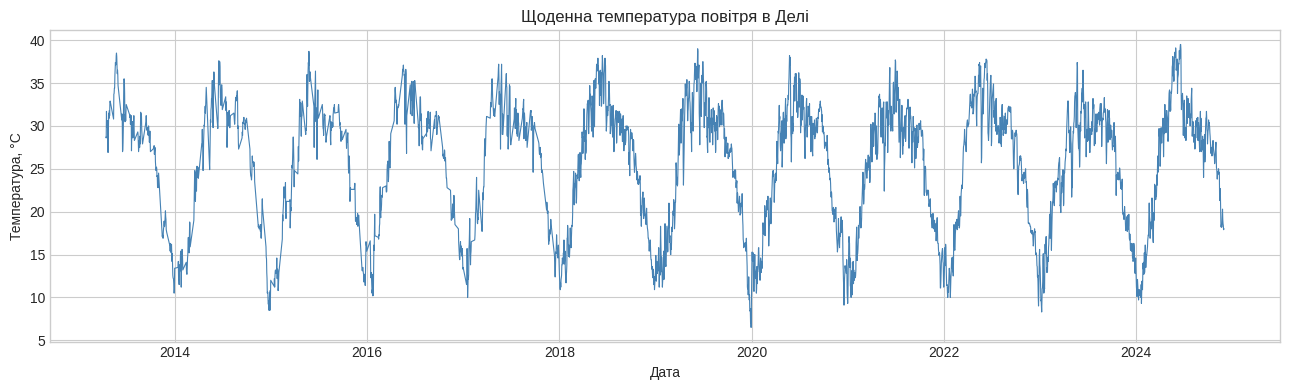

In [7]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(temperature.index, temperature.values, lw=0.8, color='steelblue')
ax.set(title='Щоденна температура повітря в Делі', xlabel='Дата', ylabel='Температура, °C')
plt.tight_layout()
plt.show()

Ковзне середнє

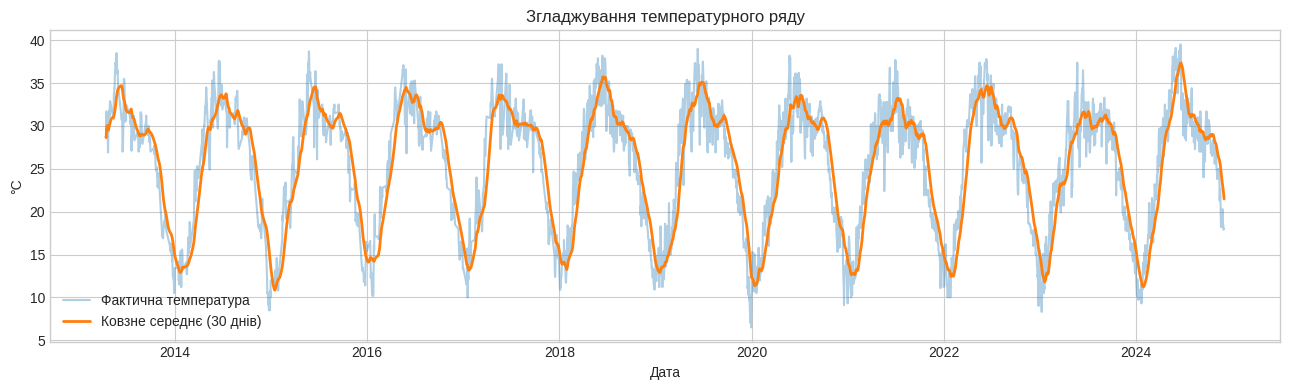

In [8]:
moving_avg = temperature.rolling(30, min_periods=1).mean()
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(temperature.index, temperature, alpha=0.35, label='Фактична температура')
ax.plot(moving_avg.index, moving_avg, lw=2, label='Ковзне середнє (30 днів)')
ax.set(title='Згладжування температурного ряду', ylabel='°C', xlabel='Дата')
ax.legend()
plt.tight_layout()
plt.show()

Розподіл температури

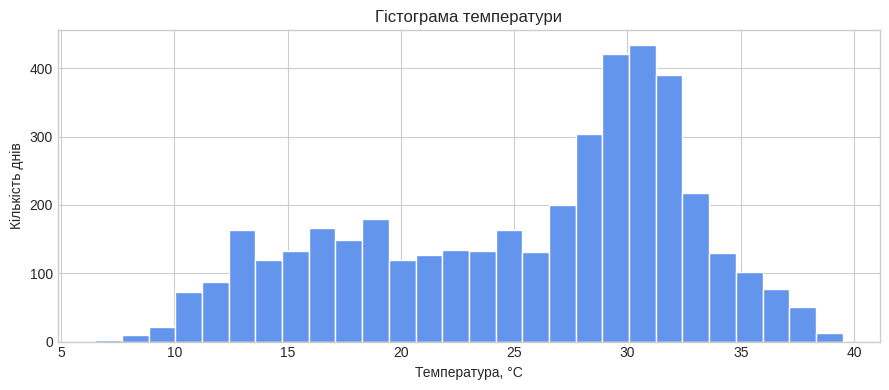

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(temperature.dropna(), bins=28, edgecolor='white', color='cornflowerblue')
ax.set(title='Гістограма температури', xlabel='Температура, °C', ylabel='Кількість днів')
plt.tight_layout()
plt.show()

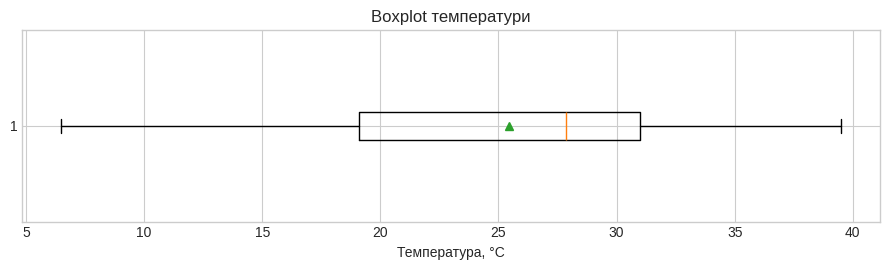

Потенційні викиди за правилом IQR: 0


In [10]:
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.boxplot(temperature.values, vert=False, showmeans=True)
ax.set(title='Boxplot температури', xlabel='Температура, °C')
plt.tight_layout()
plt.show()
q1, q3 = temperature.quantile([0.25, 0.75])
iqr = q3 - q1
print('Потенційні викиди за правилом IQR:', int(((temperature < q1 - 1.5 * iqr) | (temperature > q3 + 1.5 * iqr)).sum()))

Аналіз автокореляції
ACF

PACF

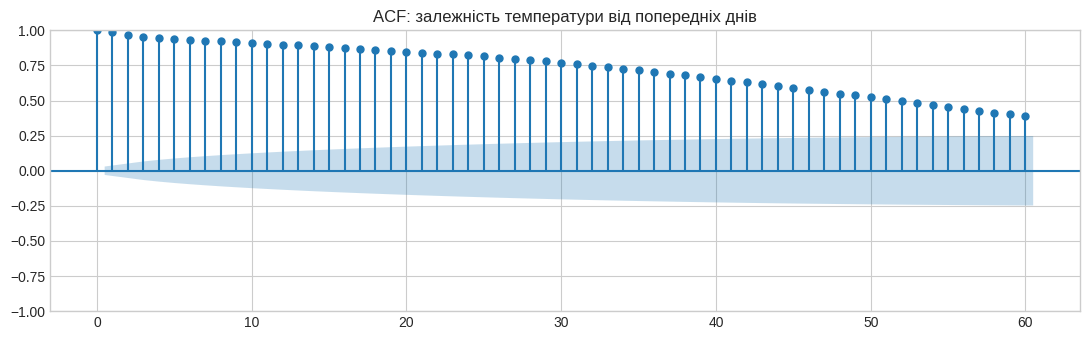

In [11]:
fig, ax = plt.subplots(figsize=(11, 3.5))
plot_acf(temperature, lags=min(60, len(temperature) - 1), ax=ax)
ax.set_title('ACF: залежність температури від попередніх днів')
plt.tight_layout()
plt.show()

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

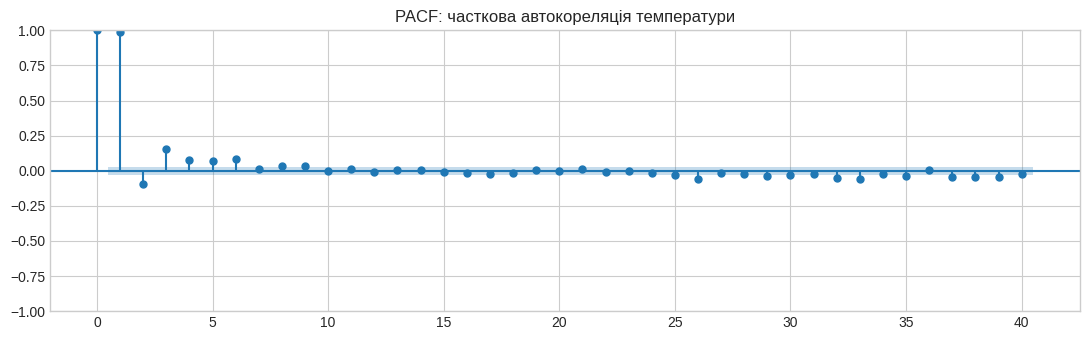

Кореляція із вчорашнім днем: 0.985
Кореляція із попереднім тижнем: 0.928


In [12]:
fig, ax = plt.subplots(figsize=(11, 3.5))
plot_pacf(temperature, lags=min(40, len(temperature) // 2 - 1), method='ywm', ax=ax)
ax.set_title('PACF: часткова автокореляція температури')
plt.tight_layout()
plt.show()
print('Кореляція із вчорашнім днем:', round(temperature.autocorr(lag=1), 3))
print('Кореляція із попереднім тижнем:', round(temperature.autocorr(lag=7), 3))

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [13]:
split = int(len(temperature) * 0.8)
train = temperature.iloc[:split].copy()
test = temperature.iloc[split:].copy()
assert len(train) > 30 and len(test) > 0
print('Навчальна вибірка:', len(train), train.index.min().date(), '—', train.index.max().date())
print('Тестова вибірка:', len(test), test.index.min().date(), '—', test.index.max().date())

def metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    if len(actual) != len(predicted):
        raise ValueError('Різна довжина фактичних та прогнозованих значень')
    valid = np.abs(actual) > 1e-8
    return {'MAE': mean_absolute_error(actual, predicted),
            'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
            'MAPE (%)': np.mean(np.abs((actual[valid] - predicted[valid]) / actual[valid])) * 100 if valid.any() else np.nan}

Навчальна вибірка: 3399 2013-04-14 — 2022-08-03
Тестова вибірка: 850 2022-08-04 — 2024-11-30


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [14]:
arima_model = ARIMA(train, order=(3, 1, 2)).fit()
arima_pred = pd.Series(np.asarray(arima_model.forecast(steps=len(test))), index=test.index, name='ARIMA')
print(arima_pred.head())

DATE
2022-08-04    30.437751
2022-08-05    30.107506
2022-08-06    29.841701
2022-08-07    29.633088
2022-08-08    29.468006
Freq: D, Name: ARIMA, dtype: float64


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [15]:
print(arima_model.summary())

                               SARIMAX Results                                
Dep. Variable:                   temp   No. Observations:                 3399
Model:                 ARIMA(3, 1, 2)   Log Likelihood               -5389.778
Date:                Sun, 01 Nov 2026   AIC                          10791.556
Time:                        07:21:10   BIC                          10828.342
Sample:                    04-14-2013   HQIC                         10804.704
                         - 08-03-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.9586      0.017    116.323      0.000       1.926       1.992
ar.L2         -1.1603      0.026    -44.746      0.000      -1.211      -1.110
ar.L3          0.1965      0.014     13.584      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

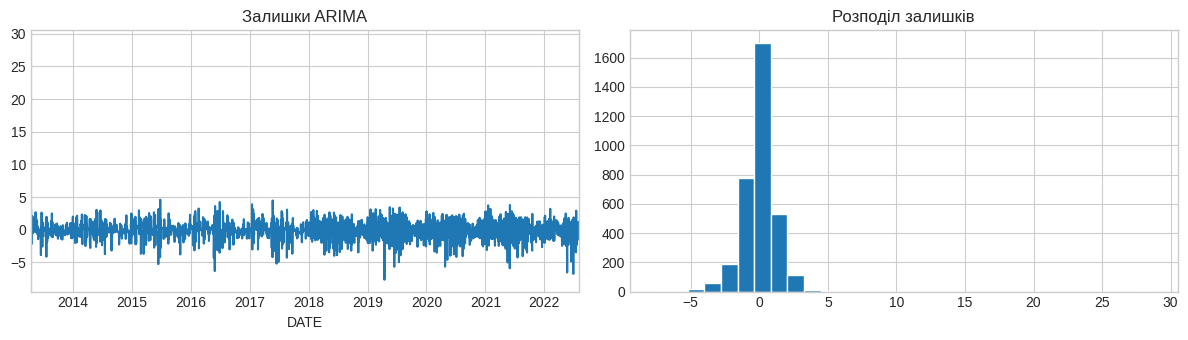

Середнє значення залишків: 0.0077


In [16]:
residuals = pd.Series(arima_model.resid).dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
residuals.plot(ax=axes[0], title='Залишки ARIMA')
axes[1].hist(residuals, bins=30, edgecolor='white')
axes[1].set_title('Розподіл залишків')
plt.tight_layout()
plt.show()
print('Середнє значення залишків:', round(residuals.mean(), 4))

In [17]:
score_arima = metrics(test, arima_pred)
print('ARIMA:', {key: round(value, 3) for key, value in score_arima.items()})

ARIMA: {'MAE': 5.609, 'RMSE': np.float64(6.995), 'MAPE (%)': np.float64(29.736)}


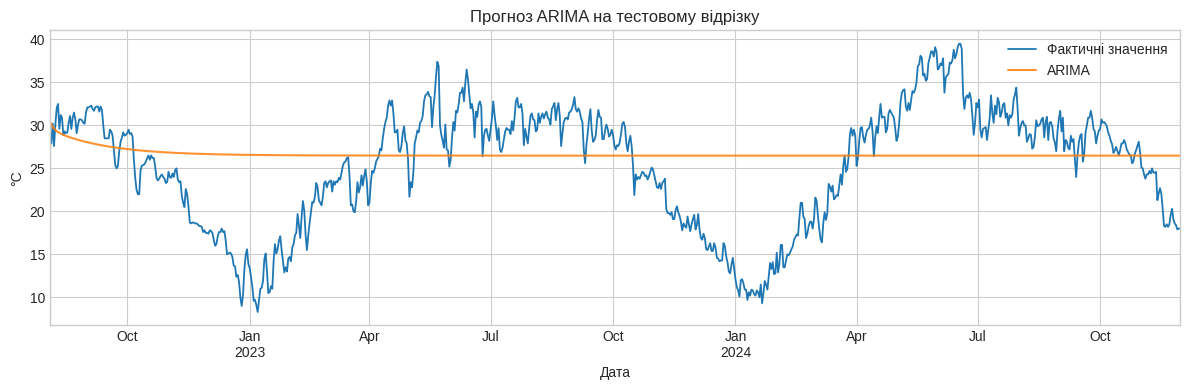

In [18]:
ax = test.plot(figsize=(12, 4), label='Фактичні значення', lw=1.3)
arima_pred.plot(ax=ax, label='ARIMA', alpha=0.85)
ax.set(title='Прогноз ARIMA на тестовому відрізку', ylabel='°C', xlabel='Дата')
ax.legend()
plt.tight_layout()
plt.show()

PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [19]:
prophet_train = pd.DataFrame({'ds': train.index, 'y': train.values})
prophet_dates = pd.DataFrame({'ds': test.index})
display(prophet_train.head())

,ds,y
0,2013-04-14,28.7
1,2013-04-15,28.6
2,2013-04-16,31.7
3,2013-04-17,29.9
4,2013-04-18,30.6


In [20]:
prophet_model = Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False,
                        changepoint_prior_scale=0.05)
prophet_model.fit(prophet_train)

Прогноз

In [21]:
prophet_result = prophet_model.predict(prophet_dates)
prophet_pred = pd.Series(prophet_result['yhat'].to_numpy(), index=test.index, name='Prophet')
display(prophet_result[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].head())

,ds,yhat,yhat_lower,yhat_upper
0,2022-08-04,30.472997,27.963683,33.033595
1,2022-08-05,30.501332,27.875004,33.135372
2,2022-08-06,30.522214,27.945635,33.035810
3,2022-08-07,30.534157,27.983928,32.919005
4,2022-08-08,30.675759,28.100400,33.152722


In [22]:
score_prophet = metrics(test, prophet_pred)
print('Prophet:', {key: round(value, 3) for key, value in score_prophet.items()})

Prophet: {'MAE': 2.067, 'RMSE': np.float64(2.646), 'MAPE (%)': np.float64(9.342)}


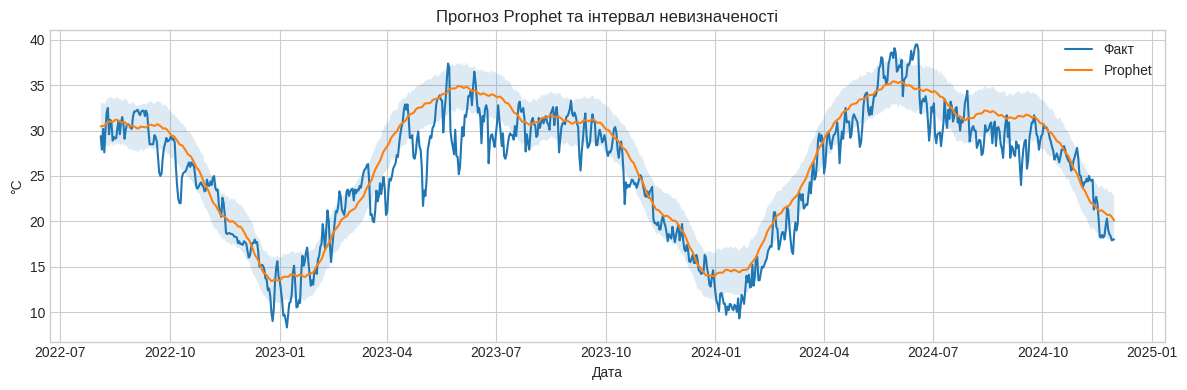

In [23]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(test.index, test, label='Факт')
ax.plot(prophet_pred.index, prophet_pred, label='Prophet')
ax.fill_between(test.index, prophet_result['yhat_lower'].to_numpy(),
                prophet_result['yhat_upper'].to_numpy(), alpha=0.15)
ax.set(title='Прогноз Prophet та інтервал невизначеності', ylabel='°C', xlabel='Дата')
ax.legend()
plt.tight_layout()
plt.show()

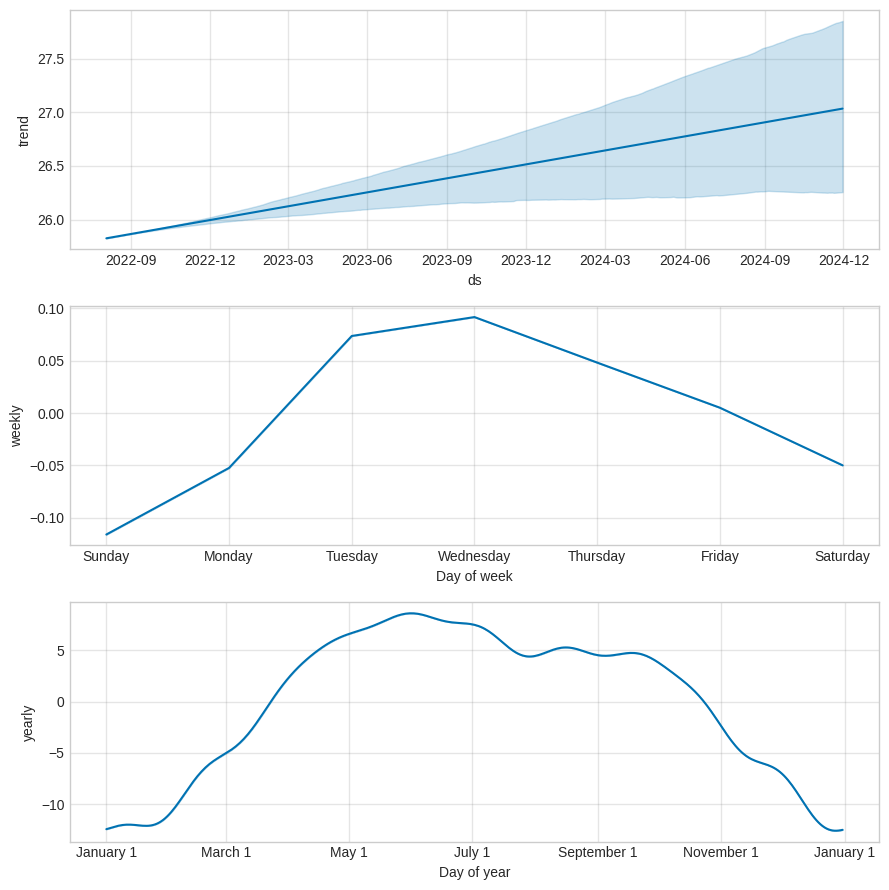

In [24]:
prophet_model.plot_components(prophet_result)
plt.show()

ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [25]:
LOOKBACK = 30
scaler = MinMaxScaler()
scaled_train = scaler.fit_transform(train.to_numpy().reshape(-1, 1)).ravel()

def sequences(values, lookback):
    x, y = [], []
    for i in range(lookback, len(values)):
        x.append(values[i-lookback:i])
        y.append(values[i])
    return np.asarray(x).reshape(-1, lookback, 1), np.asarray(y)

X_train_lstm, y_train_lstm = sequences(scaled_train, LOOKBACK)
print('X_train:', X_train_lstm.shape, 'y_train:', y_train_lstm.shape)

X_train: (3369, 30, 1) y_train: (3369,)


In [26]:
cut = int(len(X_train_lstm) * 0.9)
X_fit, X_val = X_train_lstm[:cut], X_train_lstm[cut:]
y_fit, y_val = y_train_lstm[:cut], y_train_lstm[cut:]
print('Train:', X_fit.shape, '| Validation:', X_val.shape)
print('Тестовий період починається після останнього дня навчальної вибірки:', test.index[0].date())

Train: (3032, 30, 1) | Validation: (337, 30, 1)
Тестовий період починається після останнього дня навчальної вибірки: 2022-08-04


In [27]:
lstm_model = Sequential([
    Input(shape=(LOOKBACK, 1)),
    LSTM(32),
    Dropout(0.15),
    Dense(1)
])
lstm_model.compile(optimizer='adam', loss='mse')

Epoch 1/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - loss: 0.1162 - val_loss: 0.0103
Epoch 2/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0137 - val_loss: 0.0064
Epoch 3/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0109 - val_loss: 0.0061
Epoch 4/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0099 - val_loss: 0.0056
Epoch 5/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0087 - val_loss: 0.0053
Epoch 6/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0078 - val_loss: 0.0052
Epoch 7/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0076 - val_loss: 0.0048
Epoch 8/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0074 - val_loss: 0.0047
Epoch 9/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0070 - val_loss: 0.0045
Epoch 10/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0067 - val_loss: 0.0043
Epoch 11/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0065 - val_loss: 0.0042
Epoch 12/40
95/95 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0059 - val_l

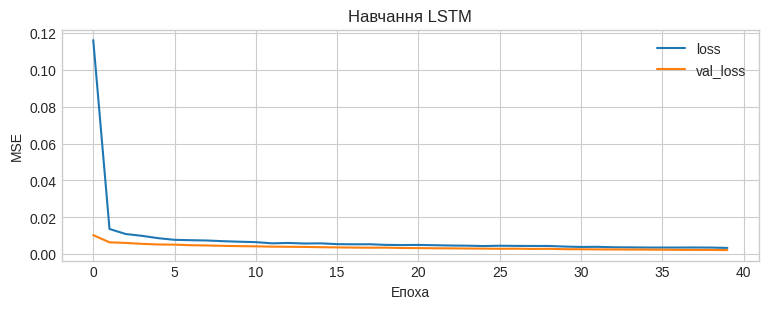

In [28]:
early_stop = EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)
training_history = lstm_model.fit(
    X_fit, y_fit, validation_data=(X_val, y_val),
    epochs=40, batch_size=32, callbacks=[early_stop], verbose=1,
    shuffle=False
)
pd.DataFrame(training_history.history)[['loss', 'val_loss']].plot(
    title='Навчання LSTM', xlabel='Епоха', ylabel='MSE', figsize=(9, 3))
plt.show()

In [29]:
lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,157 (51.40 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 8,772 (34.27 KB)

In [30]:
window_values = scaled_train[-LOOKBACK:].tolist()
lstm_forecast_scaled = []
for _ in range(len(test)):
    input_block = np.asarray(window_values[-LOOKBACK:], dtype=np.float32).reshape(1, LOOKBACK, 1)
    prediction = float(lstm_model(input_block, training=False).numpy()[0, 0])
    lstm_forecast_scaled.append(prediction)
    window_values.append(prediction)
lstm_pred = pd.Series(scaler.inverse_transform(
    np.array(lstm_forecast_scaled).reshape(-1, 1)).ravel(), index=test.index, name='LSTM')
print('Отримано', len(lstm_pred), 'рекурсивних прогнозів LSTM без підглядання у test')

Отримано 850 рекурсивних прогнозів LSTM без підглядання у test


In [31]:
assert lstm_pred.index.equals(test.index)
print('Початок прогнозування:', lstm_pred.index[0])
print('Кінець прогнозування:', lstm_pred.index[-1])

Початок прогнозування: 2022-08-04 00:00:00
Кінець прогнозування: 2024-11-30 00:00:00


In [32]:
score_lstm = metrics(test, lstm_pred)
print('LSTM:', {key: round(value, 3) for key, value in score_lstm.items()})

LSTM: {'MAE': 5.851, 'RMSE': np.float64(7.88), 'MAPE (%)': np.float64(33.446)}


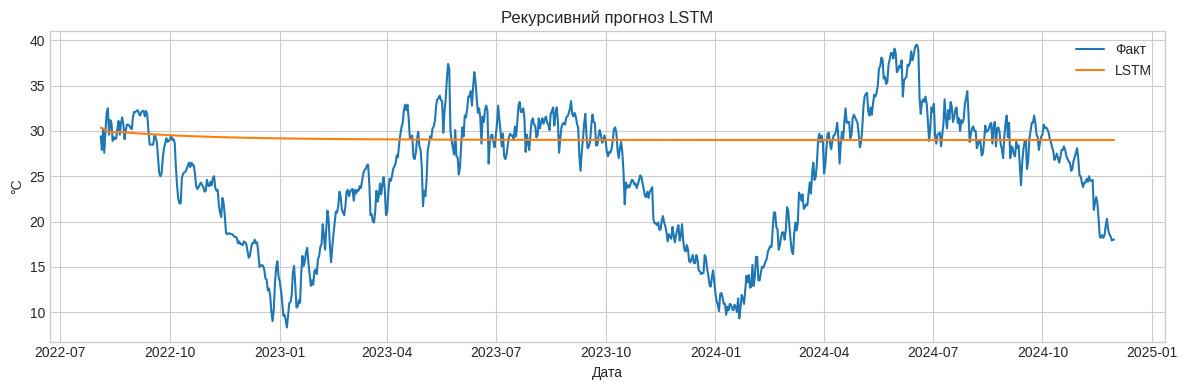

In [33]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(test.index, test, label='Факт')
ax.plot(lstm_pred.index, lstm_pred, label='LSTM')
ax.set(title='Рекурсивний прогноз LSTM', xlabel='Дата', ylabel='°C')
ax.legend()
plt.tight_layout()
plt.show()

Порівняння моделей

Порівняння точності:


,MAE,RMSE,MAPE (%)
Prophet,2.067,2.646,9.342
ARIMA,5.609,6.995,29.736
LSTM,5.851,7.880,33.446


Найкраща модель за RMSE: Prophet


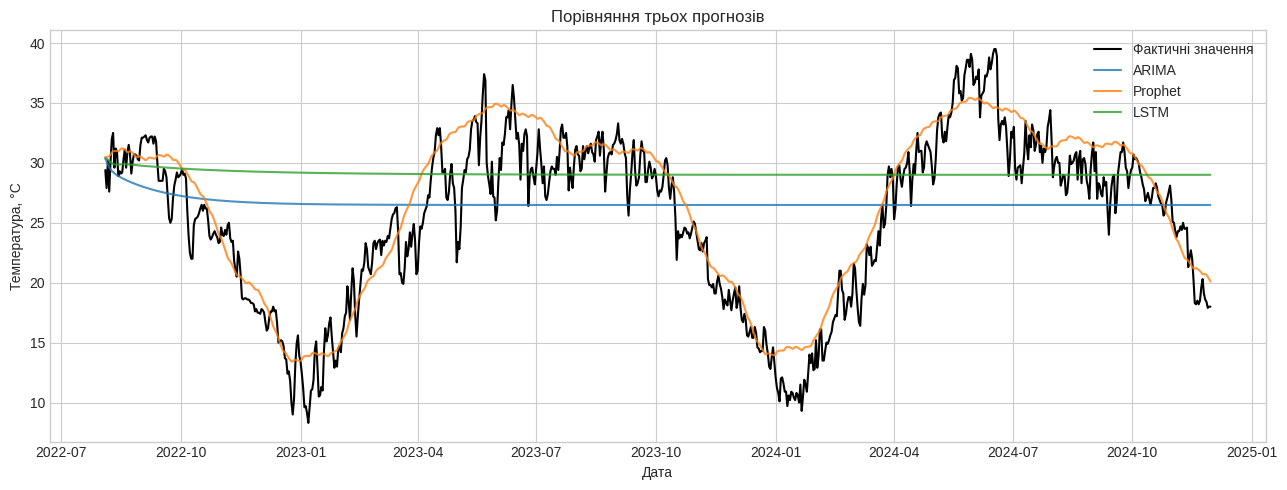

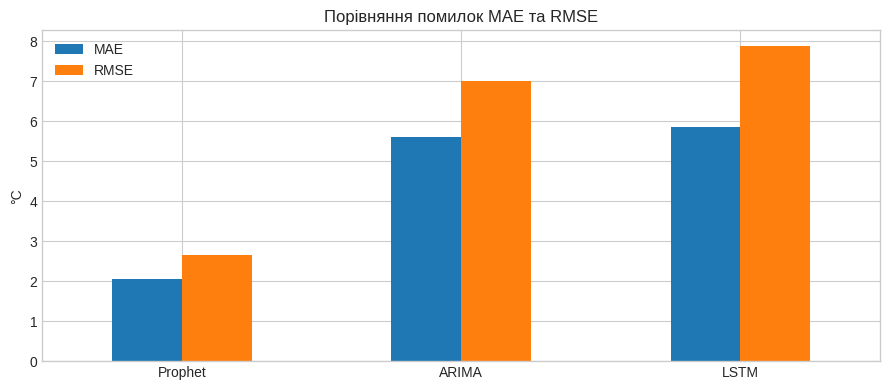

In [34]:
report = pd.DataFrame({'ARIMA': score_arima, 'Prophet': score_prophet, 'LSTM': score_lstm}).T
report = report.sort_values('RMSE')
print('Порівняння точності:')
display(report.round(3))
best = report.index[0]
print('Найкраща модель за RMSE:', best)

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(test.index, test, label='Фактичні значення', color='black', lw=1.5)
for prediction, title in [(arima_pred, 'ARIMA'), (prophet_pred, 'Prophet'), (lstm_pred, 'LSTM')]:
    ax.plot(prediction.index, prediction, label=title, alpha=0.8)
ax.set(title='Порівняння трьох прогнозів', xlabel='Дата', ylabel='Температура, °C')
ax.legend()
plt.tight_layout()
plt.show()

report.plot(kind='bar', y=['MAE', 'RMSE'], figsize=(9, 4), rot=0,
            title='Порівняння помилок MAE та RMSE')
plt.ylabel('°C')
plt.tight_layout()
plt.show()

## Висновок

Під час лабораторної роботи я проаналізував часовий ряд температури в Делі, перевірив дані на пропуски та побудував графіки, зокрема ACF і PACF. Потім порівняв прогнози ARIMA, Prophet і LSTM на тестовій частині даних.

Найточнішою виявилася **Prophet**: MAE — **2,067**, RMSE — **2,646**, MAPE — **9,342%**. У ARIMA показники гірші (RMSE **6,995**), а LSTM дала найбільшу похибку (RMSE **7,880**). На мою думку, Prophet краще впоралася з цим рядом завдяки врахуванню сезонності температури.